In [30]:
import pandas as pd
import numpy as np

In [31]:
data= pd.read_csv("C:/Users/shrid/Downloads/mlpractice/Admission_Predict.csv")

In [32]:
data

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65
...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67


In [33]:
data['Admit'] = (data['Chance of Admit ']>0.87).astype(int)
data

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65,0
...,...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82,0
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84,0
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91,1
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67,0


In [34]:
data = data.drop(columns=['Chance of Admit ','Serial No.'])
data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [35]:
ap.isna().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
Chance of Admit      0
dtype: int64

In [36]:
data.duplicated().sum()

np.int64(0)

In [41]:
data= data.fillna(data.median(numeric_only=True))

In [42]:
ap.isnull().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
Chance of Admit      0
dtype: int64

In [43]:
from sklearn.model_selection import train_test_split

In [44]:
x= data.drop(columns=['Admit'])
y= data['Admit']

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.20,random_state=42)

In [45]:
x

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,337,118,4,4.5,4.5,9.65,1.0
1,324,107,4,4.0,4.5,8.87,1.0
2,316,104,3,3.0,3.5,8.00,1.0
3,322,110,3,3.5,2.5,8.67,1.0
4,314,103,2,2.0,3.0,8.21,0.0
...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0
396,325,107,3,3.0,3.5,9.11,1.0
397,330,116,4,5.0,4.5,9.45,1.0
398,312,103,3,3.5,4.0,8.78,0.0


In [46]:
y

0      1
1      0
2      0
3      0
4      0
      ..
395    0
396    0
397    1
398    0
399    1
Name: Admit, Length: 400, dtype: int64

In [48]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score,recall_score, f1_score

In [134]:
model_entropy = DecisionTreeClassifier(criterion='entropy')
model_entropy.fit(x_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [135]:
y_pred_test= model_entropy.predict(x_test)

In [136]:
confusion_matrix(y_test,y_pred_test)

array([[58,  4],
       [ 1, 17]])

In [137]:
accuracy = accuracy_score(y_test,y_pred_test)
precision = precision_score(y_test,y_pred_test)
recall = recall_score(y_test,y_pred_test)
f1 = f1_score(y_test,y_pred_test)

In [138]:
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.9375
Precision: 0.8095238095238095
Recall: 0.9444444444444444
F1 Score: 0.8717948717948718


In [139]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree


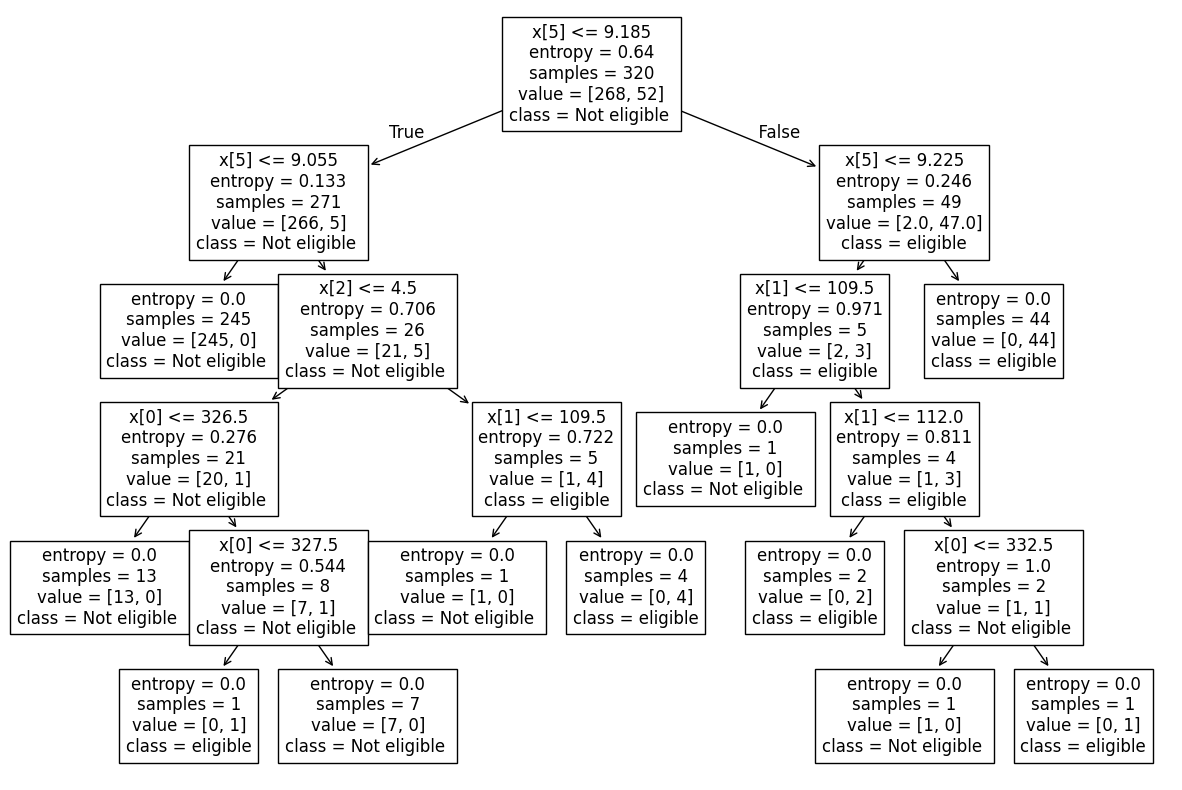

In [146]:
plt.figure(figsize=(15,10))
plot_tree(model_entropy,class_names=["Not eligible ", "eligible"])
plt.show()

In [147]:
model_gini = DecisionTreeClassifier(criterion='gini')
model_gini.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [148]:
y_pred_test_ginni = model_gini.predict(x_test)

In [149]:
confusion_matrix(y_test,y_pred_test_ginni)

array([[59,  3],
       [ 1, 17]])

In [150]:
accuracy_gini = accuracy_score(y_test,y_pred_test_ginni)
precision_gini = precision_score(y_test,y_pred_test_ginni)
recall_gini = recall_score(y_test,y_pred_test_ginni)
f1_gini = f1_score(y_test,y_pred_test_ginni)

In [151]:
print(f"Accuracy: {accuracy_gini}")
print(f"Precision: {precision_gini}")
print(f"Recall: {recall_gini}")
print(f"F1 Score: {f1_gini}")

Accuracy: 0.95
Precision: 0.85
Recall: 0.9444444444444444
F1 Score: 0.8947368421052632


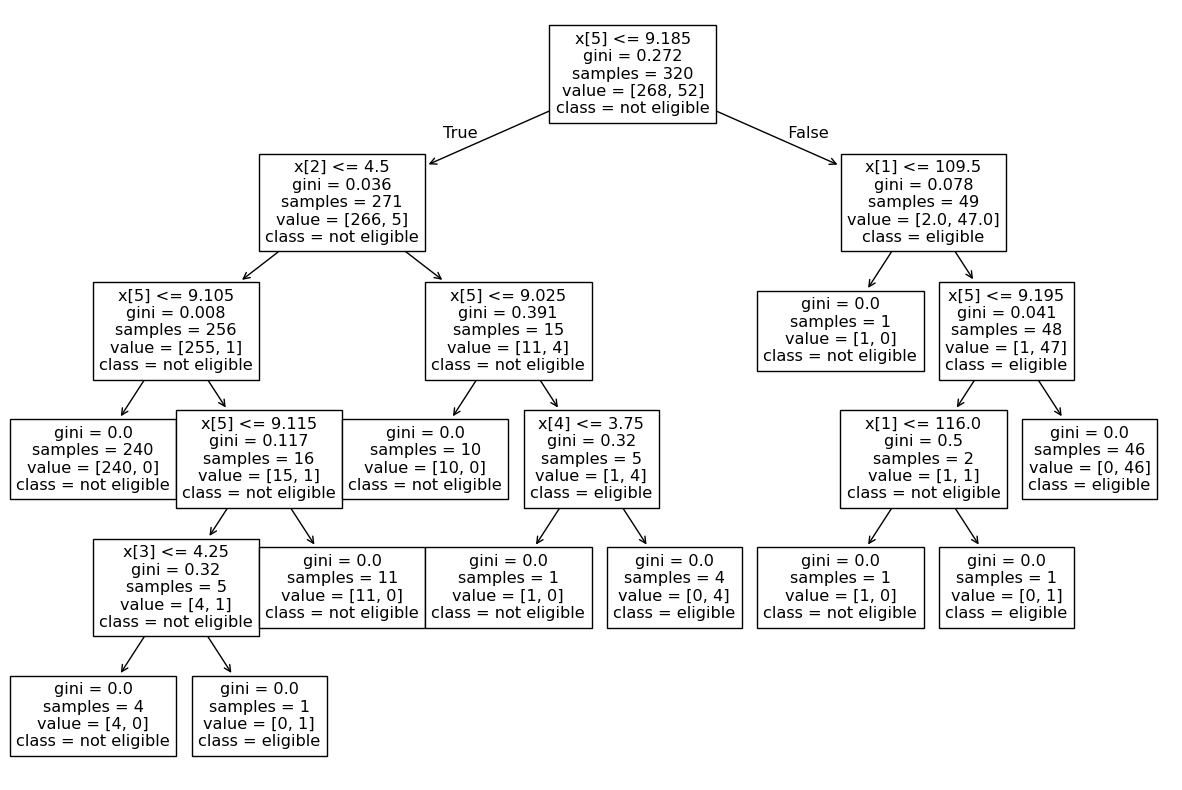

In [153]:
plt.figure(figsize=(15,10))
plot_tree(model_gini,class_names=["not eligible","eligible"])
plt.show()

Naive Bayes classifier

In [92]:
from sklearn.naive_bayes import GaussianNB


In [94]:
model_nb = GaussianNB()
model_nb.fit(x_train, y_train)

,priors,None
,var_smoothing,1e-09


In [154]:
y_pred_test_nb = model_nb.predict(x_test)

In [155]:
confussion_matrix_nb = confusion_matrix(y_test,y_pred_test_nb)
confussion_matrix_nb

array([[57,  5],
       [ 1, 17]])

In [156]:
accuracy_nb = accuracy_score(y_test,y_pred_test_nb)
precision_nb = precision_score(y_test,y_pred_test_nb)
recall_nb = recall_score(y_test,y_pred_test_nb)
f1_nb = f1_score(y_test,y_pred_test_nb)

In [157]:
print(f"Accuracy: {accuracy_nb}")
print(f"Precision: {precision_nb}")
print(f"Recall: {recall_nb}")
print(f"F1 Score: {f1_nb}")

Accuracy: 0.925
Precision: 0.7727272727272727
Recall: 0.9444444444444444
F1 Score: 0.85


In [109]:
x_train

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
3,322,110,3,3.5,2.5,8.67,1.0
18,318,110,3,4.0,3.0,8.80,0.0
202,340,120,5,4.5,4.5,9.91,1.0
250,320,104,3,3.0,2.5,8.57,1.0
274,315,100,1,2.0,2.5,7.95,0.0
...,...,...,...,...,...,...,...
71,336,112,5,5.0,5.0,9.76,1.0
106,329,111,4,4.5,4.5,9.18,1.0
270,306,105,2,2.5,3.0,8.22,1.0
348,302,99,1,2.0,2.0,7.25,0.0


In [159]:
x_new = x_train[['GRE Score','TOEFL Score']]

In [160]:
nb1 = GaussianNB()
nb1.fit(x_new,y_train)
y_pred_new= nb1.predict(x_new)

In [164]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

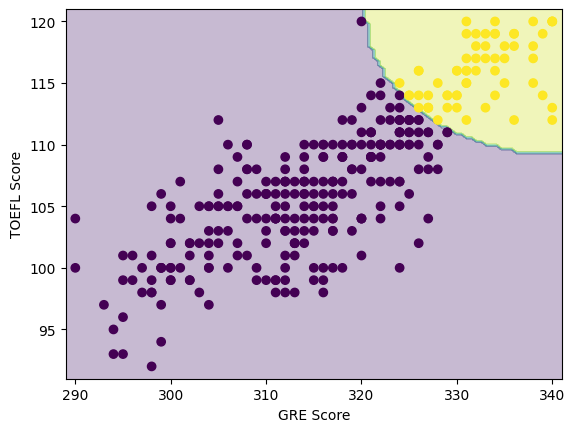

In [165]:
DecisionBoundaryDisplay.from_estimator(nb1,x,response_method='predict',alpha=0.3)
plt.scatter(x_new['GRE Score'] ,x_new['TOEFL Score'],c =y_pred_new )

In [113]:
data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [114]:
gre = float(input("GRE Score (290-340): "))
toefl = float(input("TOEFL Score (90-120): "))
rating = float(input("University Rating (1-5): "))
sop = float(input("SOP Strength (1-5): "))
lor = float(input("LOR Strength (1-5): "))
cgpa = float(input("CGPA (1-10): "))
research = float(input("Research Experience (1 for Yes, 0 for No): "))

GRE Score (290-340):  299
TOEFL Score (90-120):  105
University Rating (1-5):  3
SOP Strength (1-5):  4
LOR Strength (1-5):  2
CGPA (1-10):  9.98
Research Experience (1 for Yes, 0 for No):  1


In [172]:
new_data = pd.DataFrame([{
    "GRE Score": gre,
    "TOEFL Score": toefl,
    "University Rating": rating,
    "SOP": sop,
    "LOR ": lor,
    "CGPA": cgpa,
    "Research": research
}])

new_data = new_data[x_train.columns]
new_data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,299.0,105.0,3.0,4.0,2.0,9.98,1.0


In [176]:
prediction_entropy = model_entropy.predict(new_data)[0]
print("prediction by entropy model")

if prediction_entropy == 0:
    print("Not eligible for admission")
else:
    print("Eligible for admission")

prediction by entropy model
Eligible for admission


In [175]:
prediction = model_gini.predict(new_data)[0]
print("prediction by gini model")

if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

prediction by gini model
You are not eligible for admission


In [177]:
prediction = model_nb.predict(new_data)[0]
print("prediction by navie bayes model")
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

prediction by navie bayes model
You are not eligible for admission
